# Superstore Sales Analysis
Python, Pandas, MySQL, SQLAlchemy, Matplotlib, Seaborn

## 0. Libraries install (sirf ek baar, naye environment mein)

In [4]:
%pip install pandas numpy matplotlib seaborn sqlalchemy mysql-connector-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Data load

In [5]:
import pandas as pd

df = pd.read_csv("../data/train.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## 2. Data inspect

In [6]:
df.shape

(9800, 18)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [8]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

## 3. Cleaning

In [10]:
# Missing Postal Code bharo (rows delete nahi karte)
df["Postal Code"] = df["Postal Code"].fillna(0).astype(int)

# Dates ko date type mein badlo (format dd/mm/yyyy)
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)

In [11]:
print(df.isnull().sum().sum())
df[["Order Date", "Ship Date"]].dtypes

0


Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

## 4. Naye columns

In [12]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df[["Order Date", "Year", "Month", "Month Name", "Ship Days"]].head()

,Order Date,Year,Month,Month Name,Ship Days
0,2017-11-08,2017,11,November,3
1,2017-11-08,2017,11,November,3
2,2017-06-12,2017,6,June,4
3,2016-10-11,2016,10,October,7
4,2016-10-11,2016,10,October,7


## 5. Cleaned data save

In [13]:
df.to_csv("../data/cleaned_superstore.csv", index=False)

## 6. MySQL connection
Password prompt mein type karo. Isse password notebook mein save nahi hota, GitHub pe safe rehta hai.

In [ ]:
import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

password = getpass.getpass("MySQL root password: ")

url = URL.create(
    "mysql+mysqlconnector",
    username="root",
    password= password,
    host="localhost",
    database="superstore_db",
)
engine = create_engine(url)

In [15]:
df.to_sql("superstore_sales", engine, if_exists="replace", index=False)

9800

In [16]:
pd.read_sql("SELECT COUNT(*) AS total_rows FROM superstore_sales", engine)

,total_rows
0,9800


## 7. SQL analysis

In [17]:
pd.read_sql("SELECT ROUND(SUM(Sales), 2) AS total_sales FROM superstore_sales", engine)

,total_sales
0,2261536.78


In [18]:
cat = pd.read_sql("""
    SELECT Category, ROUND(SUM(Sales), 2) AS total_sales
    FROM superstore_sales
    GROUP BY Category
    ORDER BY total_sales DESC
""", engine)
cat

,Category,total_sales
0,Technology,827455.87
1,Furniture,728658.58
2,Office Supplies,705422.33


In [19]:
reg = pd.read_sql("""
    SELECT Region, ROUND(SUM(Sales), 2) AS total_sales
    FROM superstore_sales
    GROUP BY Region
    ORDER BY total_sales DESC
""", engine)
reg

,Region,total_sales
0,West,710219.68
1,East,669518.73
2,Central,492646.91
3,South,389151.46


In [20]:
top = pd.read_sql("""
    SELECT `Product Name`, ROUND(SUM(Sales), 2) AS total_sales
    FROM superstore_sales
    GROUP BY `Product Name`
    ORDER BY total_sales DESC
    LIMIT 10
""", engine)
top

,Product Name,total_sales
0,Canon imageCLASS 2200 Advanced Copier,61599.82
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,GBC DocuBind TL300 Electric Binding System,19823.48
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
6,Hewlett Packard LaserJet 3310 Copier,18839.69
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
8,GBC DocuBind P400 Electric Binding System,17965.07
9,High Speed Automatic Electric Letter Opener,17030.31


## 8. Charts

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

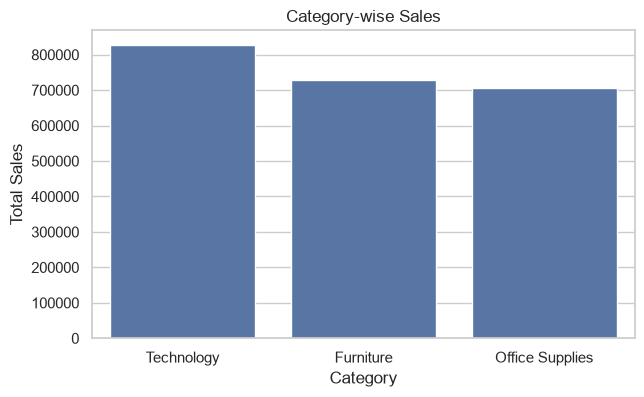

In [22]:
plt.figure(figsize=(7, 4))
sns.barplot(data=cat, x="Category", y="total_sales")
plt.title("Category-wise Sales")
plt.ylabel("Total Sales")
plt.show()

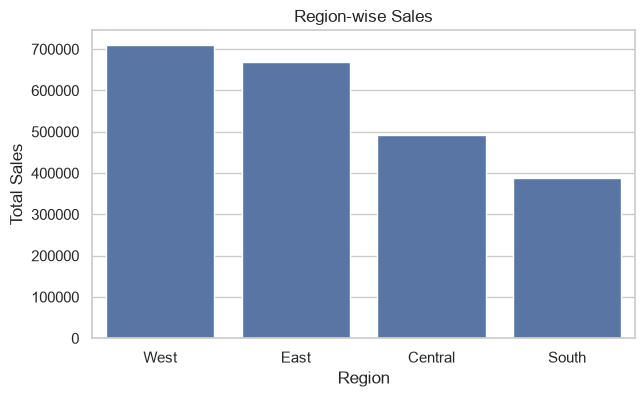

In [23]:
plt.figure(figsize=(7, 4))
sns.barplot(data=reg, x="Region", y="total_sales")
plt.title("Region-wise Sales")
plt.ylabel("Total Sales")
plt.show()

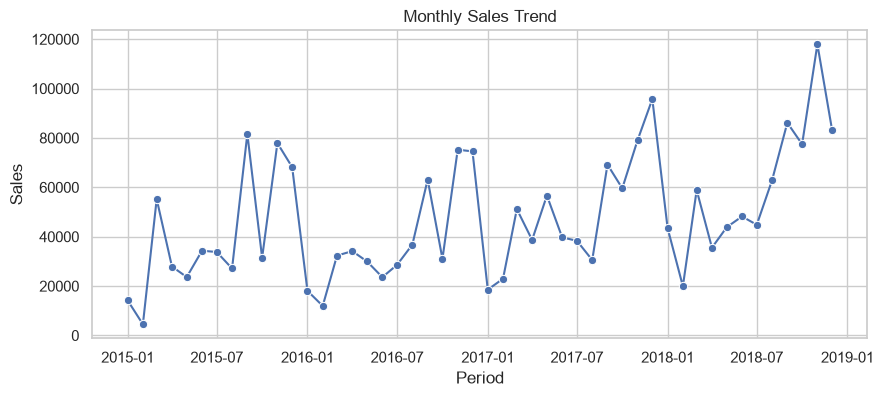

In [24]:
monthly = df.groupby(["Year", "Month"])["Sales"].sum().reset_index()
monthly["Period"] = pd.to_datetime(monthly[["Year", "Month"]].assign(day=1))

plt.figure(figsize=(10, 4))
sns.lineplot(data=monthly, x="Period", y="Sales", marker="o")
plt.title("Monthly Sales Trend")
plt.show()

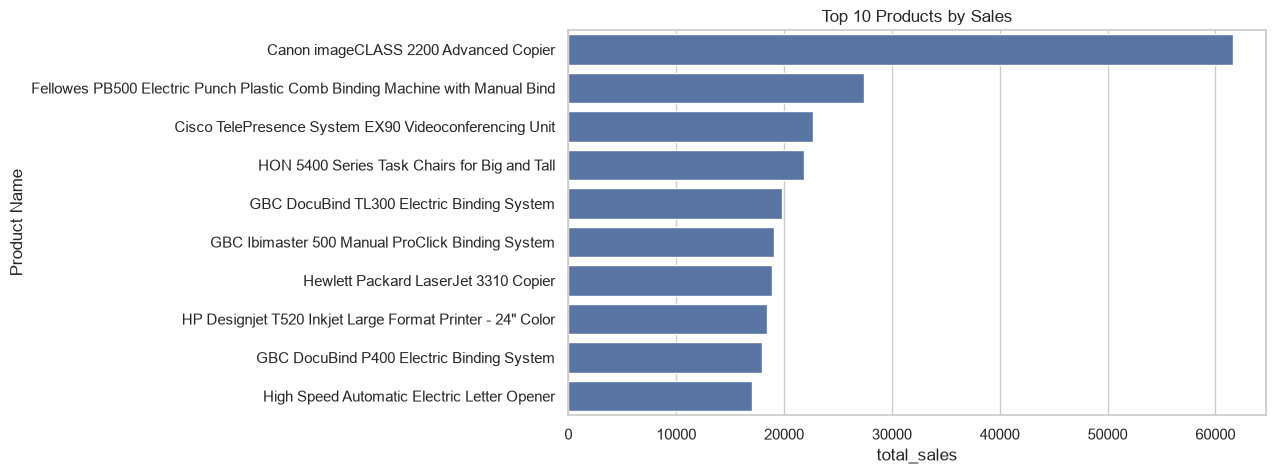

In [25]:
plt.figure(figsize=(9, 5))
sns.barplot(data=top, y="Product Name", x="total_sales")
plt.title("Top 10 Products by Sales")
plt.show()

## 9. Insights ke numbers

In [26]:
yearly = df.groupby("Year")["Sales"].sum()
print(yearly.round(0))
print((yearly.pct_change() * 100).round(1))

Year
2015    479856.0
2016    459436.0
2017    600193.0
2018    722052.0
Name: Sales, dtype: float64
Year
2015     NaN
2016    -4.3
2017    30.6
2018    20.3
Name: Sales, dtype: float64


In [27]:
df.groupby("Month Name")["Sales"].sum().sort_values(ascending=False).head(3)

Month Name
November     350161.7110
December     321480.1695
September    300103.4117
Name: Sales, dtype: float64

## Key Insights
- Top-selling category: Technology
- Top-performing region: West
- Peak sales month: December
- Best-selling product: Canon imageCLASS 2200 Advanced Copier
- Sales trend: yearly numbers cell (section 9) dekh ke likho